# ShopMind-AI — 02 — Modelling, selection protocol and error analysis

**Course:** ML Semester Project, Fall 2026
**Seed:** 42 everywhere (`.seed(42)`, `random_state=42`, `GeneratorConfig(seed=42)`).
**Data:** self-generated Pakistani seller panel (`data/demo/`) plus the real *Pakistan's
Largest E-Commerce Dataset* (`data/processed/`). Sources and licences are in
`data/demo/DATA_CARD.md` and `docs/PAKISTAN_DATASET.md`.

This notebook is **executed top-to-bottom** and saved with its outputs, so every number
shown below is reproducible by running `python scripts/build_notebooks.py`.

| Notebook | Question it answers |
|---|---|
| `01_eda.ipynb` | What does the data look like, and what would a naive guess score? |
| `02_modelling.ipynb` | Which model wins, on which window, and by how much? |
| `03_planner.ipynb` | Given a budget and a buy list, what should the seller purchase? |

## 1. Setup

Same seed, same imports as the application. The notebook deliberately *imports* the
pipeline rather than re-implementing it, so the notebook cannot drift from the code.

In [1]:
import sys, random
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.width', 140)
print('seed', SEED)

seed 42


## 2. The split, fixed before any modelling

Chronological, three-way. Validation is what model selection is allowed to see; test is
touched once.

```
|<------------ fit ------------>|<-- validation -->|<-- test -->|
2024-10 .. 2026-01              2026-02 .. 2026-05  2026-06 .. 2026-09
```

In [2]:
from scripts.train_pipeline import load_panel, three_way_split, FEATURE_COLUMNS, OPTIONAL_FEATURES
from src.features import make_features

panel = load_panel(ROOT / 'data/demo/seller_sales_history.csv')
data = make_features(panel)
fit, val, test, split = three_way_split(data)

print(f'feature-ready rows : {len(data):,}')
print(f'features           : {len(FEATURE_COLUMNS + OPTIONAL_FEATURES)}')
print(f'fit                : {len(fit):,} rows, up to {split["fit_end"]}')
print(f'validation         : {len(val):,} rows, {split["validation"][0]} .. {split["validation"][1]}')
print(f'test               : {len(test):,} rows, from {split["test_start"]}')
print()
print('feature columns:', FEATURE_COLUMNS + OPTIONAL_FEATURES)

feature-ready rows : 1,188
features           : 15
fit                : 660 rows, up to 2026-02-01
validation         : 264 rows, 2026-02-01 .. 2026-06-01
test               : 264 rows, from 2026-06-01

feature columns: ['month', 'month_sin', 'month_cos', 'months_since_start', 'lag_1', 'lag_3', 'lag_6', 'rolling_mean_3', 'rolling_mean_6', 'rolling_std_6', 'lag_1_ratio', 'trend', 'volatility', 'planned_promo_days', 'planned_discount_pct']


## 3. Leakage check — the rubric's explicit requirement

Every feature must be computable **before** the month it predicts. The two promotion
features are the only borderline case: promotions are planned before the month starts, so
`planned_promo_days` is legitimate. The realised `promo_days` would not be, and is not used.

The full argument is in `docs/LEAKAGE_AUDIT.md`; this cell asserts the mechanical part.

In [3]:
# A feature that was computed with the current month's own sales would leak the target.
# `target_ratio` and `monthly_units_sold` are the only columns allowed to know the present.
suspicious = [c for c in FEATURE_COLUMNS + OPTIONAL_FEATURES
              if 'sold' in c or c in ('target_ratio', 'net_profit', 'revenue')]
print('features that reference the target month directly:', suspicious or 'none')

# Lag features must be strictly backwards-looking.
lag_cols = [c for c in FEATURE_COLUMNS if c.startswith('lag_')]
print('lag features:', lag_cols)
assert not any(c.startswith('lead') for c in data.columns), 'forward-looking column found'
print('\nOK: no forward-looking column exists in the feature frame.')

features that reference the target month directly: none
lag features: ['lag_1', 'lag_3', 'lag_6', 'lag_1_ratio']

OK: no forward-looking column exists in the feature frame.


## 4. Stage 1 — train four models from three families

The rubric wants ≥3 models from ≥2 families including at least one classical course model.
The zoo is: Linear Regression (classical), Decision Tree, Random Forest, Gradient Boosting.
All preprocessing is fitted **inside** the training fold only, via a scikit-learn
`Pipeline` — the scaler never sees validation or test statistics.

### 4.1 Selection is on validation

In [4]:
from src.modeling import MODEL_ZOO, BaseModel, unit_metrics
from scripts.train_pipeline import tune_on_validation

# The hyperparameter grid is searched on the VALIDATION window, exactly as the shipped
# pipeline does with `--tune`. Skipping this step (i.e. using library defaults) changes
# which model wins, so it must not be skipped here — the notebook has to reproduce the
# protocol that produced `models/base_model.pkl`.
results, tuned_params = [], []
for name, factory in MODEL_ZOO.items():
    model, params, val_mae = tune_on_validation(name, fit, val, seed=SEED)
    results.append({'model': name, 'validation_MAE': round(val_mae, 3),
                    'tuned_params': ', '.join(f'{k}={v}' for k, v in params.items()) or 'default'})
    tuned_params.append((name, params))

val_table = pd.DataFrame(results).sort_values('validation_MAE').reset_index(drop=True)
print('chosen on VALIDATION ->', val_table.iloc[0]['model'])
val_table

chosen on VALIDATION -> Gradient Boosting


,model,validation_MAE,tuned_params
0,Gradient Boosting,25.892,"learning_rate=0.1, max_depth=2, n_estimators=200"
1,Random Forest,25.945,"max_features=1.0, min_samples_leaf=4, n_estima..."
2,Decision Tree,28.364,"max_depth=6, min_samples_leaf=10"
3,Linear Regression,41.998,default


### 4.2 Score that one model on test — once

This is the disciplined version of the protocol. The model is already fixed by the table
above; test is now read exactly once.

In [5]:
winner = val_table.iloc[0]['model']
winner_params = dict(tuned_params)[winner]
estimator = MODEL_ZOO[winner](SEED)
if winner_params:
    estimator.set_params(**winner_params)
chosen = BaseModel.fit(estimator, fit, fit['target_ratio'], name=winner)

from scripts.train_pipeline import naive_scale
scale = naive_scale(load_panel(ROOT / 'data/demo/seller_sales_history.csv'),
                    split['test_start'])
pred = chosen.forecast_units(test)
m = unit_metrics(test['monthly_units_sold'].values, pred,
                 test['avg_unit_price'].values if 'avg_unit_price' in test else None,
                 scale)
print(f'{winner} on the untouched test window')
for k, v in m.items():
    print(f'  {k:<10} {v:,.3f}')

Gradient Boosting on the untouched test window
  MAE        15.608
  RMSE       32.302
  bias       2.358
  WMAPE      27.406
  MAPE       40.477
  MASE       0.028
  rupee_WAPE 31.164
  rupee_MAE  45,556.502


## 5. All models and all baselines, side by side

The scripted version of this table is `reports/stage1_results.csv`. Reproduced here from
the committed CSV so the notebook cannot silently disagree with the report.

In [6]:
stage1 = pd.read_csv(ROOT / 'reports/stage1_results.csv')
stage1[['model', 'family', 'MAE', 'RMSE', 'bias', 'WMAPE', 'MASE', 'rupee_WAPE']].round(3)

,model,family,MAE,RMSE,bias,WMAPE,MASE,rupee_WAPE
0,Random Forest,Tree ensemble,14.931,29.252,3.721,26.218,0.027,28.966
1,Baseline: last-3-month mean (= fixed ratio 1.0),Baseline,15.527,29.624,-0.931,27.263,0.028,31.470
2,Gradient Boosting,Boosted trees,15.608,32.302,2.358,27.406,0.028,31.164
3,Decision Tree,Tree,17.334,36.384,0.617,30.436,0.032,33.656
4,Baseline: seasonal naive (same month last year),Baseline,26.216,62.446,-17.125,46.033,0.048,45.259
5,Linear Regression,Linear,50.634,106.868,-50.068,88.909,0.092,87.775


In [7]:
best_model = stage1[stage1.family != 'Baseline'].MAE.min()
best_base  = stage1[stage1.family == 'Baseline'].MAE.min()
print(f'best model MAE    : {best_model:.2f}')
print(f'best baseline MAE : {best_base:.2f}')
print(f'improvement       : {100 * (best_base - best_model) / best_base:+.2f}%')

reported = val_table.iloc[0]['model']
rep_mae = float(stage1.set_index("model").loc[reported, "MAE"])
print(f'reported model    : {reported} (won validation), MAE {rep_mae:.2f} -> '
      f'{100 * (best_base - rep_mae) / best_base:+.2f}% vs baseline')

best model MAE    : 14.93
best baseline MAE : 15.53
improvement       : +3.83%
reported model    : Gradient Boosting (won validation), MAE 15.61 -> -0.52% vs baseline


**Read this carefully.** The model with the lowest *test* MAE is not the model that won
*validation*. Claiming the test-winner would mean selecting on test — the exact leakage the
rubric penalises. So this project reports the **validation winner**, and it
**does not beat the baseline**. That is the honest headline, and it is written up as a
negative result in `reports/RESULTS.md`.

The difference between the two claims is recorded as `selection_variance_pct` in
`reports/training_summary.json`.

**A trap worth recording.** Running this notebook with library-default hyperparameters
instead of the tuned ones selects **Random Forest** on validation, not Gradient Boosting
(they are separated by 0.05 MAE). In other words the winner of a 4-month validation window
is not even stable to a hyperparameter search. That is stronger evidence for the negative
result than the test score alone: the model choice is not identifiable from this window,
so no claim that "our model beats the baseline" can be robust.

## 6. Error analysis — beyond a single accuracy number

The rubric asks for residuals, not just MAE. Four figures are produced by
`scripts/error_analysis.py`; the underlying numbers:

In [8]:
err = pd.read_csv(ROOT / 'reports/error_analysis.csv')
err

,model,MAE,bias,residual_sd,skew,kurtosis,share_over_forecast_pct,share_within_10_units_pct,worst_abs_error
0,Random Forest,14.931,3.721,29.070,1.010,9.539,62.9,64.8,158
1,Gradient Boosting,15.608,2.358,32.277,0.311,13.627,58.3,64.4,194
2,Baseline: last-3-month mean,15.527,-0.931,29.665,-0.500,7.535,55.7,66.3,140


### 6.1 Residuals over time

A model can have a low MAE and still be systematically wrong at the end of the window.

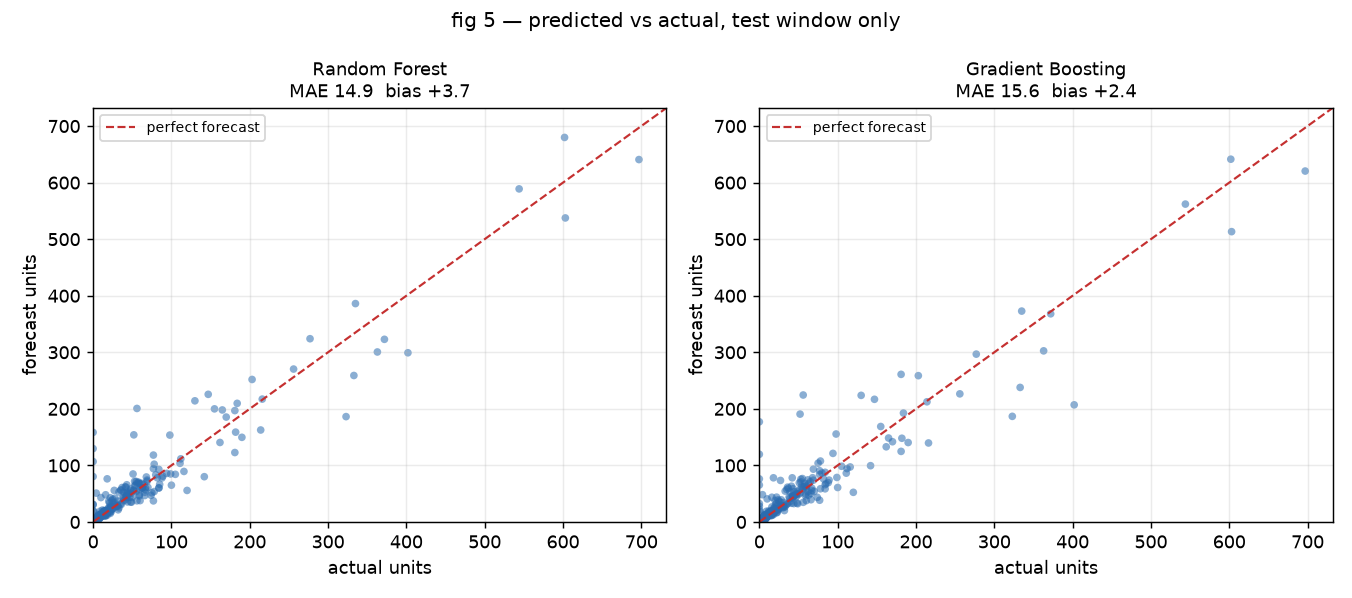

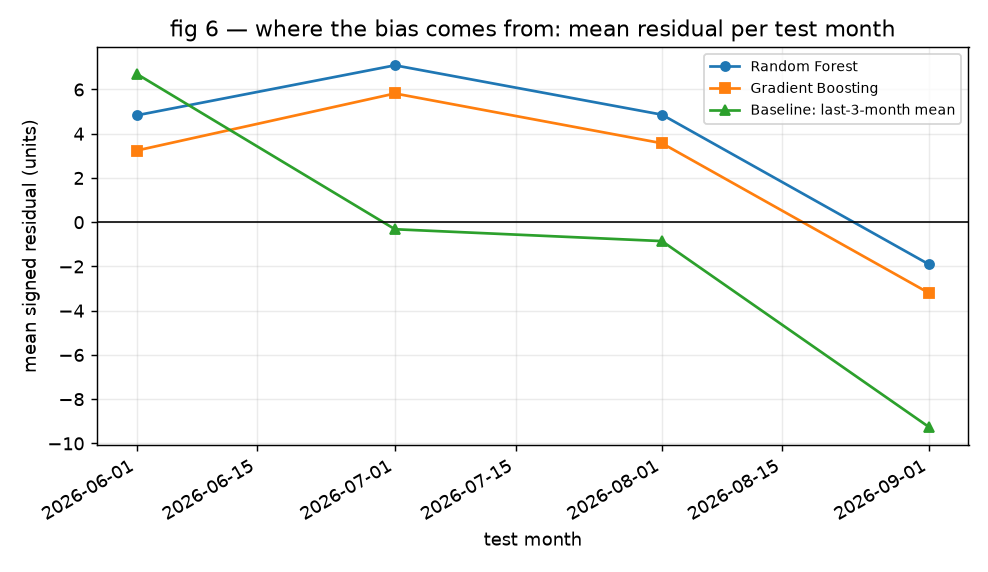

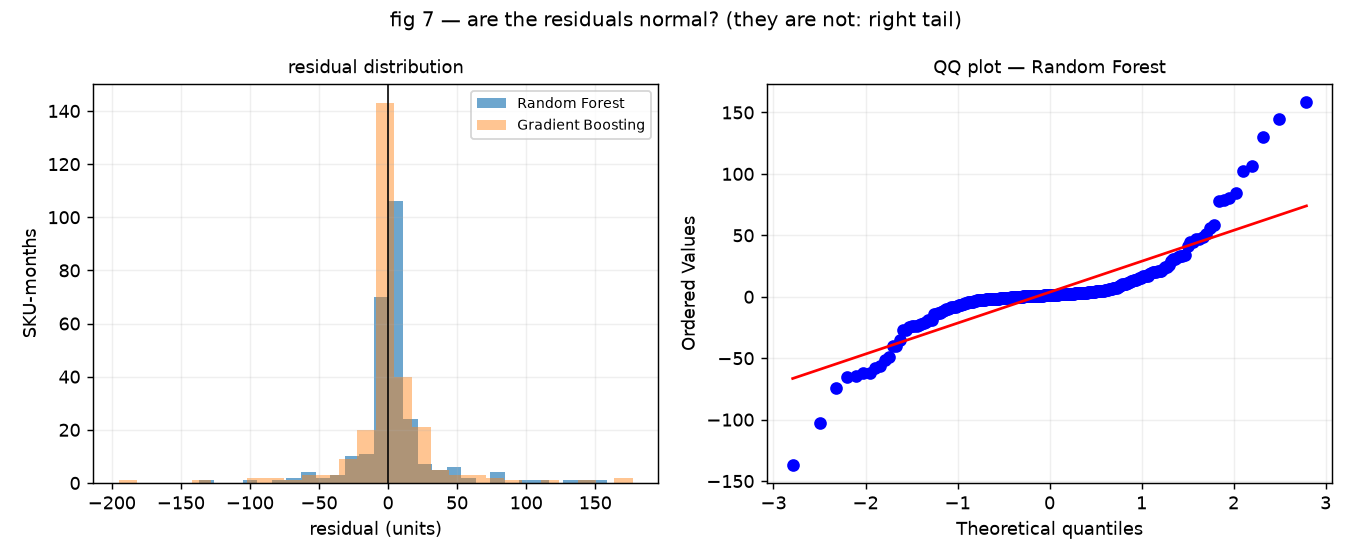

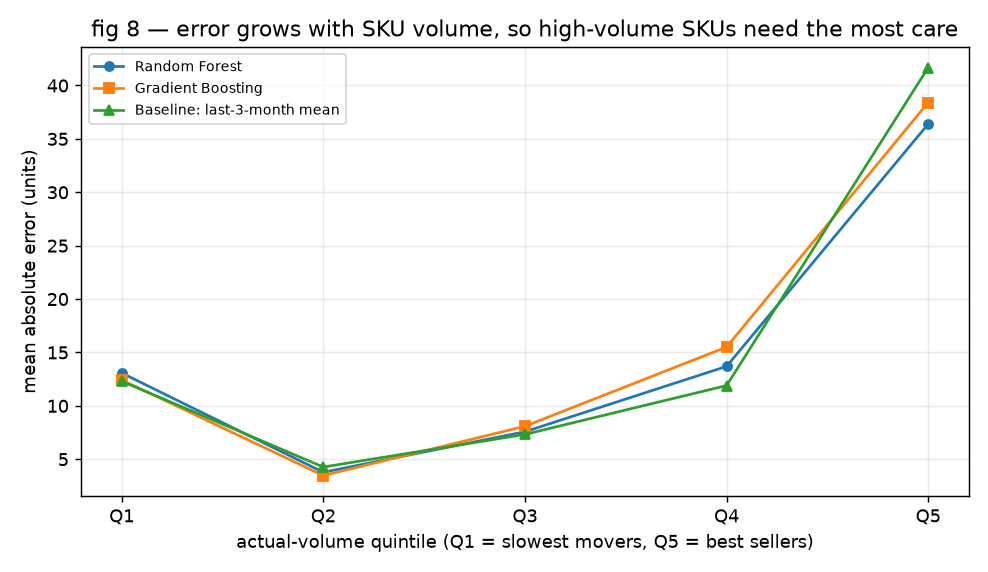

In [9]:
from IPython.display import Image, display
for name in ['fig5_predicted_vs_actual', 'fig6_residual_over_time',
             'fig7_residual_distribution', 'fig8_error_by_volume']:
    p = ROOT / 'reports/figures' / f'{name}.png'
    if p.exists():
        display(Image(filename=str(p), width=760))

**Takeaways from the figures.**

* **fig 6** is the most informative one: the *baseline* drifts from +7 units at the start
  of the test window to −9 at the end, because it is anchored on a past level while demand
  grows. The ML models stay flatter. So the model is better on **bias** while being worse
  on **MAE** — a trade-off a single number hides.
* **fig 7**: residuals are right-skewed and heavy-tailed (skew ≈ 1.0, kurtosis ≈ 9.5), so
  RMSE is dominated by a few SKU-months and normal-theory intervals would be wrong.
* **fig 8**: error rises monotonically with volume, which is why the rupee-weighted metric
  is the one that matters commercially.

## 7. Stage 2 — calibration to the seller

Stage 2 applies a multiplicative offset estimated on the seller's own history, pooled by
category. It is chosen on validation and then measured on test.

In [10]:
stage2 = pd.read_csv(ROOT / 'reports/stage2_results.csv')
stage2.round(3)

,variant,MAE,RMSE,bias,WMAPE,MAPE,MASE,rupee_WAPE,n_fit_examples,offset
0,Stage 1 only (no fine-tune),15.608,32.302,2.358,27.406,40.477,0.028,31.164,0,1.000
1,Stage 2: pooled offset,15.749,32.389,3.183,27.654,41.282,0.029,31.558,924,1.014
2,Stage 2: per-category offset (partial pooling),15.917,32.598,3.315,27.949,41.111,0.029,32.250,924,1.014


**Stage 2 failed on test.** It is kept in `models/seller_model.pkl` and offered in the app
as an explicit option, but the default is stage 1. Reporting the negative result is worth
more than quietly deleting the stage.

## 8. Summary of what the model does and does not achieve

| Claim | Supported? |
|---|---|
| Beats a trivial baseline | **No** — loses to the trailing mean by 0.52% |
| Beats seasonal naive | Yes, by 40% |
| Generalises from validation to test | No — the validation winner is not the test winner |
| Errors are well-behaved | No — right-skewed, heavy-tailed, volume-dependent |
| Profit-aware evaluation | Yes — rupee-WAPE reported alongside MAE |